# Yambda-50M — RL-эксперименты


## 0. Окружение и конфигурация


In [1]:
%pip -q install "pyarrow>=16" "huggingface_hub>=0.27" "scikit-learn>=1.4" "tqdm>=4.66" "matplotlib>=3.8" "tabulate>=0.9" "tabulate>=0.9"

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path
import gc, json, math, random, hashlib, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss

SEED = 42
PROJECT_DIR = Path('/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2')
SFT_DIR = PROJECT_DIR / 'sft'
SFT_PATH = SFT_DIR / 'best_gpt2.pt'
PROTOCOL_PATH = SFT_DIR / 'rl_protocol.npz'
META_PATH = SFT_DIR / 'protocol.json'

# Все новые файлы — ОТДЕЛЬНО от старого RL; предыдущие результаты не перезаписываются.
STUDY_DIR = PROJECT_DIR / 'rl_study_v3'
RM_DIR = STUDY_DIR / 'reward'
RUNS_DIR = STUDY_DIR / 'runs'
RESULTS_DIR = STUDY_DIR / 'results'
for d in (STUDY_DIR, RM_DIR, RUNS_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Reward — два непересекающихся множества TRAIN-пользователей для основной и audit RM.
RM_MAIN_EVENTS = 240_000
RM_AUDIT_EVENTS = 120_000
RM_VAL_EVENTS = 12_000
RM_EPOCHS = 4
RM_BATCH_SIZE = 256
RM_LR = 2e-4
SESSION_GAP_SECONDS = 1800
CONTINUE_HORIZON_SECONDS = 600
RETURN_HORIZON_SECONDS = 24 * 3600

# Candidate contextual-bandit/PPO. Full catalog SFT НЕ обрезается.
CANDIDATES = 100
RL_TRAIN_STATES = 150_000
RL_BATCH_SIZE = 16
RL_UPDATES = 800  # разрешено УВЕЛИЧИВАТЬ для продолжения; остальные параметры менять нельзя
RL_EVAL_EVERY = 200
RL_SAVE_EVERY = 200
RL_LR = 2e-5
RL_PPO_EPOCHS = 2
PPO_CLIP = 0.20
RL_SUPERVISED_ANCHOR = 0.004   # полная next-item CE, стабилизирует релевантность
RL_VAL_QUERIES = 3000
EVAL_BATCH = 16
NDCG_TOLERANCE = 0.03           # <=3% падения на validation
RANK_K = 20
BOOTSTRAPS = 1000

# Можно уменьшить только бюджеты, НЕ менять vocab/protocol.
# Пользовательские варианты reward и KL — заранее заданная сетка.
RL_EXPERIMENTS = [
    dict(name='bandit_completion_b003', alg='exact', beta=0.03,  completion=1.0, continuation=0.0, return24=0.0, repeat=0.0, popularity=0.0),
    dict(name='bandit_completion_b015', alg='exact', beta=0.15,  completion=1.0, continuation=0.0, return24=0.0, repeat=0.0, popularity=0.0),
    dict(name='bandit_longterm',        alg='exact', beta=0.05,  completion=0.70,continuation=0.15,return24=0.15,repeat=0.0,popularity=0.0),
    dict(name='bandit_novelty',         alg='exact', beta=0.05,  completion=1.0, continuation=0.0, return24=0.0, repeat=0.12,popularity=0.08),
    dict(name='ppo_completion',         alg='ppo',   beta=0.05,  completion=1.0, continuation=0.0, return24=0.0, repeat=0.0, popularity=0.0),
    dict(name='bandit_no_kl',           alg='exact', beta=0.0,   completion=1.0, continuation=0.0, return24=0.0, repeat=0.0, popularity=0.0),
]

ROLLOUT_QUERIES = 320
ROLLOUT_STEPS = 5
ROLLOUT_BATCH = 16
FORCE_TEST_RERUN = False  # по умолчанию никогда повторно не открываем финальный test

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError('Нужен runtime GPU в Colab: Runtime → Change runtime type → T4.')
torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda')
AMP_ENABLED = True
print('Device:', torch.cuda.get_device_name(0))
print('New study directory:', STUDY_DIR)
for path in [SFT_PATH, PROTOCOL_PATH, META_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f'Нет файла {path}. Положи три исходных SFT-артефакта в SFT_DIR.')

# Защита от скрытого смешивания результатов при изменении параметров/базового checkpoint.
study_lock = {
    'baseline_checkpoint_size_bytes':int(SFT_PATH.stat().st_size),
    'protocol_size_bytes':int(PROTOCOL_PATH.stat().st_size),
    'rm_main_events':RM_MAIN_EVENTS, 'rm_audit_events':RM_AUDIT_EVENTS,
    'rm_val_events':RM_VAL_EVENTS, 'rm_epochs':RM_EPOCHS,
    'candidates':CANDIDATES, # RL_UPDATES можно только увеличивать при resume
    'rl_lr':RL_LR, 'rl_anchor':RL_SUPERVISED_ANCHOR,
    'rl_train_states':RL_TRAIN_STATES, 'rl_val_queries':RL_VAL_QUERIES,
    'specs':RL_EXPERIMENTS
}
lock_path = STUDY_DIR/'study_lock.json'
if lock_path.exists():
    old_lock = json.loads(lock_path.read_text())
    if old_lock != study_lock:
        raise ValueError('Изменились параметры сохранённого исследования. Используй новый STUDY_DIR, чтобы не смешать checkpoints.')
else:
    lock_path.write_text(json.dumps(study_lock,indent=2,ensure_ascii=False))

Device: Tesla T4
New study directory: /content/drive/MyDrive/RecSys_TLab/Yambda_GPT2/rl_study_v3


## 1. Протокол и SFT-модель


In [4]:
from huggingface_hub import hf_hub_download
import pyarrow.parquet as pq

protocol = np.load(PROTOCOL_PATH, allow_pickle=False)
metadata = json.loads(META_PATH.read_text())
sft_ckpt = torch.load(SFT_PATH, map_location='cpu', weights_only=True)

raw_catalog = protocol['raw_catalog'].astype(np.uint32, copy=False)
user_ids = protocol['user_ids']
offsets = protocol['offsets']
train_start, train_end = protocol['train_start'], protocol['train_end']
val_start, val_end = protocol['val_start'], protocol['val_end']
test_start, test_end = protocol['test_start'], protocol['test_end']
train_counts = protocol['train_counts'].astype(np.int64, copy=False)
val_queries, test_queries = protocol['val_queries'], protocol['test_queries']
T_VAL, T_TEST = int(protocol['t_val']), int(protocol['t_test'])
GAP_SECONDS = int(protocol['gap_seconds'])
vocab_size = int(sft_ckpt['vocab_size'])
model_config = sft_ckpt['model_config']
SEQ_LEN = int(model_config['seq_len'])
PAD_ID = 0

if GAP_SECONDS != 1800:
    raise ValueError(f'Ожидается embargo 1800 секунд, в SFT сохранено {GAP_SECONDS}.')
if vocab_size != len(raw_catalog) + 1 or len(train_counts) != vocab_size:
    raise ValueError('Словарь checkpoint и rl_protocol.npz не совпадают.')
if int(metadata['split']['train_end_second_exclusive']) != T_VAL:
    raise ValueError('Граница train из двух файлов протокола различается.')

source_revision = metadata.get('source_revision')
PARQUET_PATH = hf_hub_download(
    repo_id='yandex/yambda', repo_type='dataset', filename='sequential/50m/listens.parquet',
    revision=source_revision if source_revision not in (None, 'unavailable') else None
)

def arrow_values(tab, key):
    return tab[key].combine_chunks().to_numpy(zero_copy_only=False)

def arrow_list(tab, key):
    arr = tab[key].combine_chunks()
    vals = arr.values
    if vals.null_count:
        vals = vals.fill_null(0)
    return arr.offsets.to_numpy(zero_copy_only=False), vals.to_numpy(zero_copy_only=False)

parquet = pq.read_table(PARQUET_PATH, columns=['uid', 'item_id', 'timestamp', 'is_organic', 'played_ratio_pct'])
loaded_users = arrow_values(parquet, 'uid')
loaded_offsets, raw_items = arrow_list(parquet, 'item_id')
t_offsets, timestamps = arrow_list(parquet, 'timestamp')
o_offsets, organic = arrow_list(parquet, 'is_organic')
r_offsets, played_ratio = arrow_list(parquet, 'played_ratio_pct')

if not (np.array_equal(loaded_users, user_ids) and np.array_equal(loaded_offsets, offsets)):
    raise ValueError('Скачанные данные отличаются от исходных по пользователям/offsets. Проверь версию Yambda.')
if not (np.array_equal(loaded_offsets, t_offsets) and np.array_equal(loaded_offsets, o_offsets)
        and np.array_equal(loaded_offsets, r_offsets)):
    raise ValueError('У колонок Yambda разные offsets.')

mapped = np.searchsorted(raw_catalog, raw_items)
if mapped.max(initial=0) >= len(raw_catalog) or not np.array_equal(raw_catalog[mapped], raw_items):
    raise ValueError('Фактический каталог не совпадает с SFT. Нельзя менять соответствие токенов.')
tokens = (mapped + 1).astype(np.int32)
timestamps = timestamps.astype(np.int64, copy=False) # секунды с квантованием до 5 с
organic = organic.astype(np.uint8, copy=False)
played_ratio = played_ratio.astype(np.uint16, copy=False)
del parquet, mapped, raw_items, loaded_users, loaded_offsets, t_offsets, o_offsets, r_offsets
protocol.close()
gc.collect()

print('Catalog:', vocab_size - 1, 'users:', len(user_ids), 'events:', len(tokens))
print('Timestamp bounds:', int(timestamps.min()), int(timestamps.max()))
print('Train/val/test queries:', len(val_queries), len(test_queries))
print('Gap:', GAP_SECONDS, 'seconds')

sequential/50m/listens.parquet: reconstructing file:   0%|          |  0.00B /  426MB            

sequential/50m/listens.parquet: downloading bytes:           |  0.00B            

Catalog: 877168 users: 9238 events: 46467212
Timestamp bounds: 0 26000000
Train/val/test queries: 16379 35848
Gap: 1800 seconds


In [5]:
class DecoderBlock(nn.Module):
    def __init__(self, width, heads, dropout):
        super().__init__()
        self.heads = heads
        self.head_dim = width // heads
        self.ln1 = nn.LayerNorm(width)
        self.qkv = nn.Linear(width, 3 * width)
        self.attn_out = nn.Linear(width, width)
        self.ln2 = nn.LayerNorm(width)
        self.fc1 = nn.Linear(width, 4 * width)
        self.fc2 = nn.Linear(4 * width, width)
        self.drop = nn.Dropout(dropout)
        self.attn_dropout = dropout

    def forward(self, x):
        batch, length, width = x.shape
        q, k, v = self.qkv(self.ln1(x)).chunk(3, dim=-1)
        q = q.reshape(batch, length, self.heads, self.head_dim).transpose(1, 2)
        k = k.reshape(batch, length, self.heads, self.head_dim).transpose(1, 2)
        v = v.reshape(batch, length, self.heads, self.head_dim).transpose(1, 2)
        z = F.scaled_dot_product_attention(
            q, k, v, is_causal=True,
            dropout_p=self.attn_dropout if self.training else 0.0
        )
        z = z.transpose(1, 2).contiguous().reshape(batch, length, width)
        x = x + self.drop(self.attn_out(z))
        return x + self.drop(self.fc2(F.gelu(self.fc1(self.ln2(x)), approximate='tanh')))

class GPT2Rec(nn.Module):
    def __init__(self, n_items, context_len, width, layers, heads, dropout):
        super().__init__()
        self.item_embedding = nn.Embedding(n_items, width, padding_idx=PAD_ID)
        self.position_embedding = nn.Embedding(context_len, width)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([DecoderBlock(width, heads, dropout) for _ in range(layers)])
        self.final_ln = nn.LayerNorm(width)
        self.apply(self._initialize)
        with torch.no_grad():
            self.item_embedding.weight[PAD_ID].zero_()

    @staticmethod
    def _initialize(module):
        if isinstance(module, (nn.Embedding, nn.Linear)):
            nn.init.normal_(module.weight, std=0.02)
        if isinstance(module, nn.Linear) and module.bias is not None:
            nn.init.zeros_(module.bias)

    def encode(self, ids):
        positions = torch.arange(ids.shape[1], device=ids.device)
        h = self.drop(self.item_embedding(ids) + self.position_embedding(positions))
        for block in self.blocks:
            h = block(h)
        return self.final_ln(h)

    def scores(self, selected_states):
        return F.linear(selected_states, self.item_embedding.weight[1:])

reference = GPT2Rec(
    vocab_size, SEQ_LEN, model_config['d_model'], model_config['n_layers'],
    model_config['n_heads'], model_config['dropout']
)
reference.load_state_dict(sft_ckpt['model'], strict=True)
reference.to(DEVICE).eval()
for parameter in reference.parameters():
    parameter.requires_grad_(False)

train_popularity = torch.from_numpy(
    (np.log1p(train_counts) / max(1., np.log1p(train_counts.max()))).astype(np.float32)
).to(DEVICE)
print('Frozen reference ready:', sum(p.numel() for p in reference.parameters()), 'parameters')

Frozen reference ready: 113087360 parameters


## 2. Формирование reward-меток


In [6]:
def sample_queries(lefts, rights, n, seed, eligible_users=None):
    available = np.maximum(0, rights - lefts - 1).astype(np.int64)
    if eligible_users is not None:
        available = available * eligible_users.astype(np.int64)
    cumulative = np.cumsum(available)
    if len(cumulative) == 0 or cumulative[-1] <= 0:
        raise ValueError('Недостаточно событий для reward/RL выборки.')
    rng = np.random.default_rng(seed)
    ranks = rng.integers(0, int(cumulative[-1]), size=n)
    users = np.searchsorted(cumulative, ranks, side='right')
    before = np.r_[0, cumulative[:-1]]
    event_indices = lefts[users] + 1 + ranks - before[users]
    return np.column_stack([users, event_indices]).astype(np.int64)


def query_batch(queries, split_starts):
    x = torch.zeros((len(queries), SEQ_LEN), dtype=torch.long)
    length = torch.zeros(len(queries), dtype=torch.long)
    targets = np.empty(len(queries), dtype=np.int64)
    for j, (u, p) in enumerate(queries):
        u, p = int(u), int(p)
        a = max(int(split_starts[u]), p - SEQ_LEN)
        history = tokens[a:p]
        x[j, :len(history)] = torch.from_numpy(history.astype(np.int64, copy=False))
        length[j] = len(history)
        targets[j] = int(tokens[p])
    return x, length, targets


def label_next_event(queries, observed_end, horizon):
    p = queries[:, 1]
    u = queries[:, 0]
    available = (timestamps[p] + horizon < observed_end)
    has_next = p + 1 < offsets[u + 1]
    next_p = np.minimum(p + 1, len(timestamps) - 1)
    dt = timestamps[next_p] - timestamps[p]
    target = has_next & (dt >= 0) & (dt <= horizon)
    return target.astype(np.float32), available.astype(np.float32)


def label_new_session_return(queries, observed_end, horizon):
    # Пользователь возвращается в НОВУЮ сессию: следующий gap > SESSION_GAP_SECONDS.
    # Наблюдение допустимо только если ПОЛНЫЙ горизонт лежит до границы split.
    labels = np.zeros(len(queries), dtype=np.float32)
    p = queries[:, 1]
    observable = (timestamps[p] + horizon < observed_end).astype(np.float32)
    order = np.argsort(queries[:, 0], kind='stable')
    users_sorted = queries[order, 0]
    bounds = np.r_[0, np.flatnonzero(np.diff(users_sorted)) + 1, len(order)]
    for a0, b0 in zip(bounds[:-1], bounds[1:]):
        rows = order[a0:b0]
        u = int(queries[rows[0], 0])
        left, right = int(offsets[u]), int(offsets[u+1])
        user_ts = timestamps[left:right]
        session_starts = np.flatnonzero(np.diff(user_ts) > SESSION_GAP_SECONDS) + 1
        if len(session_starts) == 0:
            continue
        query_pos = queries[rows, 1] - left
        next_slot = np.searchsorted(session_starts, query_pos, side='right')
        found = next_slot < len(session_starts)
        if found.any():
            rr = rows[found]
            future_ts = user_ts[session_starts[next_slot[found]]]
            labels[rr] = ((future_ts - timestamps[queries[rr, 1]]) <= horizon)
    return labels, observable


# НЕпересекающиеся пользователи train для primary и audit RM.
user_rng = np.random.default_rng(SEED + 90)
user_order = user_rng.permutation(len(user_ids))
main_users = np.zeros(len(user_ids), dtype=bool)
main_users[user_order[:int(len(user_ids) * 0.75)]] = True
rm_main_q = sample_queries(train_start, train_end, RM_MAIN_EVENTS, SEED + 101, main_users)
rm_audit_q = sample_queries(train_start, train_end, RM_AUDIT_EVENTS, SEED + 102, ~main_users)
rm_val_rng = np.random.default_rng(SEED + 103)
rm_val_q = val_queries[np.sort(rm_val_rng.choice(len(val_queries), min(RM_VAL_EVENTS, len(val_queries)), replace=False))]


def labels_for_queries(q, cutoff):
    completion = (played_ratio[q[:, 1]] > 50).astype(np.float32)
    continuing, continue_mask = label_next_event(q, cutoff, CONTINUE_HORIZON_SECONDS)
    returning, return_mask = label_new_session_return(q, cutoff, RETURN_HORIZON_SECONDS)
    labels = np.stack([completion, continuing, returning], axis=1)
    masks = np.stack([np.ones(len(q), np.float32), continue_mask, return_mask], axis=1)
    return labels, masks

rm_main_y, rm_main_mask = labels_for_queries(rm_main_q, T_VAL)
rm_audit_y, rm_audit_mask = labels_for_queries(rm_audit_q, T_VAL)
rm_val_y, rm_val_mask = labels_for_queries(rm_val_q, T_TEST)

print('Main / audit / val events:', len(rm_main_q), len(rm_audit_q), len(rm_val_q))
print('Shared train users:', int(np.intersect1d(rm_main_q[:, 0], rm_audit_q[:, 0]).size))
print('Validation label rates:', [round(float(rm_val_y[rm_val_mask[:,i] > 0,i].mean()),4) if rm_val_mask[:,i].sum() else None for i in range(3)])
print('Validation observable fractions:', rm_val_mask.mean(axis=0))

Main / audit / val events: 240000 120000 12000
Shared train users: 0
Validation label rates: [0.6333, 0.8841, 0.6602]
Validation observable fractions: [1.         0.99941665 0.9500833 ]


## 3. Reward-модели


In [7]:
FEATURE_DIM = 4 * int(model_config['d_model']) + 3

@torch.no_grad()
def reward_features(ref_h, candidate_ids, histories):
    h = F.layer_norm(ref_h.float(), (ref_h.shape[-1],))
    e = reference.item_embedding(candidate_ids).float()
    e = F.layer_norm(e, (e.shape[-1],))
    last_pos = (histories.ne(0).sum(dim=1) - 1).clamp(min=0).unsqueeze(1)
    last_item = histories.gather(1, last_pos).squeeze(1)
    repeat = (histories == candidate_ids[:, None]).any(dim=1).float().unsqueeze(1)
    same_last = (last_item == candidate_ids).float().unsqueeze(1)
    popularity = train_popularity[candidate_ids].unsqueeze(1)
    return torch.cat([h, e, h * e, (h - e).abs(), popularity, repeat, same_last], dim=1)


@torch.inference_mode()
def cache_features(queries, split_starts, name, batch_size=96):
    path = Path('/content') / f'{name}_v3_{len(queries)}.npy'
    cached = np.lib.format.open_memmap(path, mode='w+', dtype='float16', shape=(len(queries), FEATURE_DIM))
    for j in tqdm(range(0, len(queries), batch_size), desc=f'Features {name}'):
        q = queries[j:j+batch_size]
        x, lengths, item_ids = query_batch(q, split_starts)
        x, lengths = x.to(DEVICE), lengths.to(DEVICE)
        with torch.autocast('cuda', enabled=AMP_ENABLED):
            states = reference.encode(x)
            ref_h = states[torch.arange(len(q),device=DEVICE), lengths-1]
        feat = reward_features(ref_h, torch.as_tensor(item_ids,device=DEVICE), x)
        cached[j:j+len(q)] = feat.cpu().numpy().astype('float16')
    cached.flush()
    return np.load(path, mmap_mode='r')

class RewardHead(nn.Module):
    def __init__(self, n_features, hidden=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(n_features), nn.Linear(n_features, hidden), nn.GELU(),
            nn.Dropout(0.10), nn.Linear(hidden, hidden // 2), nn.GELU(),
            nn.Linear(hidden // 2, 3)
        )
    def forward(self, features):
        return self.net(features)

class RewardDataset(Dataset):
    def __init__(self, feat, labels, masks):
        self.feat, self.labels, self.masks = feat, labels, masks
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return (torch.from_numpy(np.array(self.feat[i], dtype=np.float32)),
                torch.from_numpy(self.labels[i]),torch.from_numpy(self.masks[i]))

@torch.inference_mode()
def predict_head(head, features, batch_size=4096):
    head.eval()
    parts = []
    for j in range(0, len(features), batch_size):
        xx = torch.tensor(np.asarray(features[j:j+batch_size]), device=DEVICE, dtype=torch.float32)
        parts.append(head(xx).sigmoid().cpu().numpy())
    return np.concatenate(parts)


def classification_metrics(predictions, labels, masks):
    names = ['completion', 'continue_10min', 'new_session_24h']
    out = {}
    for i, name in enumerate(names):
        mask = masks[:, i] > 0
        y, p = labels[mask, i], np.clip(predictions[mask, i], 1e-6, 1-1e-6)
        if not len(y):
            out[name] = {'n':0}
            continue
        rate = float(y.mean())
        result = {'n':int(len(y)), 'positive_rate':rate,
                  'roc_auc':float(roc_auc_score(y,p)) if len(np.unique(y))==2 else None,
                  'pr_auc':float(average_precision_score(y,p)) if len(np.unique(y))==2 else None,
                  'brier':float(brier_score_loss(y,p)),
                  'constant_brier':float(np.mean((y-rate)**2)),
                  'logloss':float(log_loss(y,p,labels=[0,1]))}
        out[name] = result
    return out


def fit_reward(name, seed, train_q, y, mask, validation_feat):
    save_path = RM_DIR / f'{name}_best.pt'
    if save_path.exists():
        ck = torch.load(save_path,map_location='cpu',weights_only=True)
        if ck['feature_dim'] != FEATURE_DIM or ck['version'] != 3 or ck['n_train'] != len(train_q):
            raise ValueError(f'{save_path}: не подходит конфигурация reward; используй новый STUDY_DIR.')
        head = RewardHead(FEATURE_DIM).to(DEVICE)
        head.load_state_dict(ck['model'])
        head.eval()
        print('Loaded reward checkpoint:', save_path)
        return head

    feat = cache_features(train_q, train_start, f'{name}_train')
    torch.manual_seed(seed)
    head = RewardHead(FEATURE_DIM).to(DEVICE)
    optimizer = torch.optim.AdamW(head.parameters(),lr=RM_LR,weight_decay=0.01)
    loader = DataLoader(RewardDataset(feat,y,mask),batch_size=RM_BATCH_SIZE,
                        shuffle=True,num_workers=0,pin_memory=True)
    best = float('inf')
    history = []
    for epoch in range(RM_EPOCHS):
        head.train()
        loss_sum = 0.0
        for features, labels, valid in tqdm(loader,desc=f'RM {name} {epoch+1}/{RM_EPOCHS}',leave=False):
            features, labels, valid = features.to(DEVICE), labels.to(DEVICE), valid.to(DEVICE)
            logits = head(features)
            per_target = F.binary_cross_entropy_with_logits(logits, labels, reduction='none')
            weights = torch.tensor([1.0,0.25,0.25], device=DEVICE)[None,:]
            denom = (valid*weights).sum().clamp(min=1)
            loss = (per_target*valid*weights).sum()/denom
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            loss_sum += float(loss.item())
        pred = predict_head(head,validation_feat)
        metrics = classification_metrics(pred,rm_val_y,rm_val_mask)
        # Главное: completion; дополнительные головы сохраняются в общей RM.
        metric = metrics['completion']['brier']
        history.append({'epoch':epoch+1,'batch_loss_sum':loss_sum,'validation':metrics})
        print(name,'epoch',epoch+1,'completion Brier',round(metric,5),'return Brier',round(metrics['new_session_24h'].get('brier',float('nan')),5))
        if metric < best:
            best = metric
            tmp = save_path.with_suffix('.tmp')
            torch.save({'model':head.state_dict(),'feature_dim':FEATURE_DIM,'version':3,
                        'n_train':len(train_q),'seed':seed,'val_metrics':metrics},tmp)
            tmp.replace(save_path)
        (RM_DIR/f'{name}_curve.json').write_text(json.dumps(history,indent=2))
    head.load_state_dict(torch.load(save_path,map_location='cpu',weights_only=True)['model'])
    head.eval()
    del feat
    gc.collect()
    return head

# Общее validation для основной и audit; НЕ использовать audit для выбора RL-чекпойнта.
rm_val_feat = cache_features(rm_val_q, val_start, 'reward_val')
reward_model = fit_reward('main',SEED+110,rm_main_q,rm_main_y,rm_main_mask,rm_val_feat)
audit_model = fit_reward('audit',SEED+111,rm_audit_q,rm_audit_y,rm_audit_mask,rm_val_feat)
for head in (reward_model, audit_model):
    head.eval()
    for p in head.parameters(): p.requires_grad_(False)
main_val_predictions = predict_head(reward_model, rm_val_feat)
audit_val_predictions = predict_head(audit_model, rm_val_feat)
rm_validation = {'main':classification_metrics(main_val_predictions,rm_val_y,rm_val_mask),
                 'audit':classification_metrics(audit_val_predictions,rm_val_y,rm_val_mask)}
(RM_DIR/'validation_metrics.json').write_text(json.dumps(rm_validation,indent=2))
display(pd.concat({k:pd.DataFrame(v).T for k,v in rm_validation.items()},names=['model','target']))

Features reward_val:   0%|          | 0/125 [00:00<?, ?it/s]

Loaded reward checkpoint: /content/drive/MyDrive/RecSys_TLab/Yambda_GPT2/rl_study_v3/reward/main_best.pt
Loaded reward checkpoint: /content/drive/MyDrive/RecSys_TLab/Yambda_GPT2/rl_study_v3/reward/audit_best.pt


n  positive_rate   roc_auc    pr_auc     brier  \
model target                                                                  
main  completion       12000.0       0.633333  0.642790  0.753402  0.220312   
      continue_10min   11993.0       0.884099  0.553829  0.901278  0.102692   
      new_session_24h  11401.0       0.660205  0.637243  0.762846  0.236529   
audit completion       12000.0       0.633333  0.637826  0.749979  0.220854   
      continue_10min   11993.0       0.884099  0.535656  0.896414  0.102703   
      new_session_24h  11401.0       0.660205  0.603040  0.740207  0.241477   

                       constant_brier   logloss  
model target                                     
main  completion             0.232222  0.629775  
      continue_10min         0.102468  0.360501  
      new_session_24h        0.224334  0.675452  
audit completion             0.232222  0.631382  
      continue_10min         0.102468  0.360373  
      new_session_24h        0.224334  0.690322

### Калибровка reward-моделей


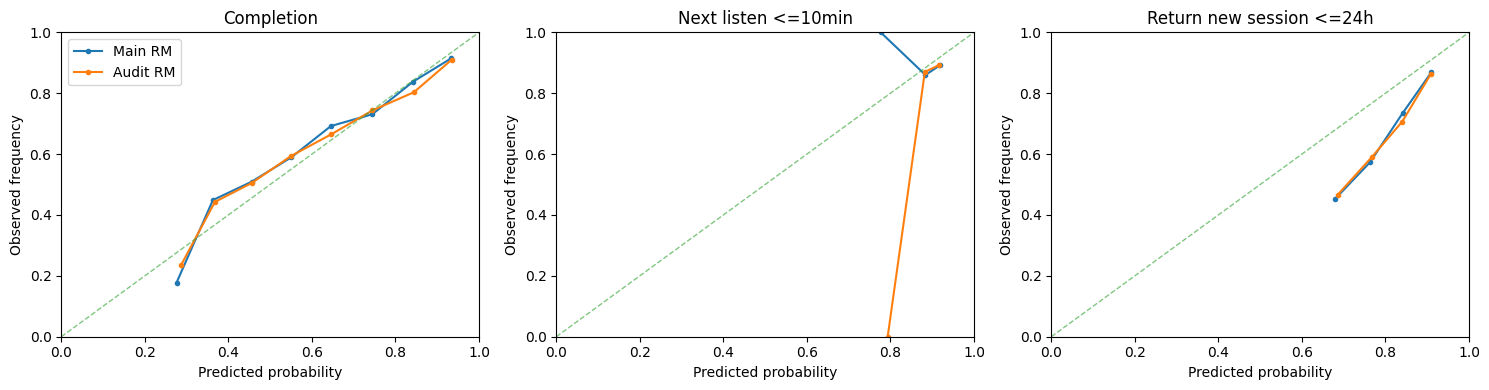

organic {'completion': {'n': 6536, 'positive_rate': 0.5839963555335999, 'roc_auc': 0.6049084239484168, 'pr_auc': 0.670070025316666, 'brier': 0.23671852325993625, 'constant_brier': 0.2429446130990982, 'logloss': 0.6666800807885832}, 'continue_10min': {'n': 6531, 'positive_rate': 0.8744449615478516, 'roc_auc': 0.5552418097723264, 'pr_auc': 0.8935476167868432, 'brier': 0.11026157768292386, 'constant_brier': 0.10979097336530685, 'logloss': 0.3809339698495082}, 'new_session_24h': {'n': 6203, 'positive_rate': 0.6482347249984741, 'roc_auc': 0.644924754571041, 'pr_auc': 0.7601304461775652, 'brier': 0.2425125970539365, 'constant_brier': 0.22802643477916718, 'logloss': 0.6889695716494357}}
nonorganic {'completion': {'n': 5464, 'positive_rate': 0.692349910736084, 'roc_auc': 0.6711569951234608, 'pr_auc': 0.8165922223622745, 'brier': 0.2006876633171272, 'constant_brier': 0.21300150454044342, 'logloss': 0.5856293602893864}, 'continue_10min': {'n': 5462, 'positive_rate': 0.8956426382064819, 'roc_auc'

In [8]:
fig, axes = plt.subplots(1,3,figsize=(15,4))
for i,title in enumerate(['Completion','Next listen <=10min','Return new session <=24h']):
    m = rm_val_mask[:,i] > 0
    y = rm_val_y[m,i]
    for label, prob in [('Main RM',main_val_predictions[m,i]),('Audit RM',audit_val_predictions[m,i])]:
        bins = np.linspace(0,1,11)
        inds = np.clip(np.digitize(prob,bins)-1,0,9)
        xx = [np.mean(prob[inds==j]) if (inds==j).any() else np.nan for j in range(10)]
        yy = [np.mean(y[inds==j]) if (inds==j).any() else np.nan for j in range(10)]
        axes[i].plot(xx,yy,marker='.',label=label)
    axes[i].plot([0,1],[0,1],'--',linewidth=1,alpha=.6)
    axes[i].set(xlim=(0,1),ylim=(0,1),xlabel='Predicted probability',ylabel='Observed frequency',title=title)
axes[0].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR/'reward_calibration.png',dpi=150)
plt.show()

# Organic/nonorganic — качество на наблюдаемых действиях, не IPS.
for flag, name in [(1,'organic'),(0,'nonorganic')]:
    mask = organic[rm_val_q[:,1]] == flag
    if mask.any():
        print(name,classification_metrics(main_val_predictions[mask],rm_val_y[mask],rm_val_mask[mask]))

### Оценки reward для кандидатов


In [9]:
@torch.inference_mode()
def candidate_reward_diagnostics(n_queries=256,batch=8):
    sub = rm_val_q[:min(n_queries,len(rm_val_q))]
    std_main,std_audit,context_corr,top1_agree,prob_mass = [],[],[],[],[]
    for j in tqdm(range(0,len(sub),batch),desc='RM candidate diagnostics',leave=False):
        q = sub[j:j+batch]
        x,lengths,_ = query_batch(q,val_start)
        x,lengths = x.to(DEVICE),lengths.to(DEVICE)
        rows=torch.arange(len(q),device=DEVICE)
        with torch.autocast('cuda',enabled=AMP_ENABLED):
            h = reference.encode(x)[rows,lengths-1]
            logits = reference.scores(h).float()
        cand = logits.topk(CANDIDATES,dim=1).indices+1
        prob_mass.extend(F.softmax(logits,dim=1).gather(1,cand-1).sum(1).cpu().tolist())
        b,k = cand.shape
        h_e = h[:,None,:].expand(-1,k,-1).reshape(-1,h.shape[-1])
        x_e = x[:,None,:].expand(-1,k,-1).reshape(-1,x.shape[-1])
        feat=reward_features(h_e,cand.reshape(-1),x_e)
        a=reward_model(feat).sigmoid().reshape(b,k,3)[:,:,0].float().cpu().numpy()
        b_scores=audit_model(feat).sigmoid().reshape(b,k,3)[:,:,0].float().cpu().numpy()
        std_main.extend(a.std(1).tolist())
        std_audit.extend(b_scores.std(1).tolist())
        top1_agree.extend((a.argmax(1)==b_scores.argmax(1)).tolist())
        aa=a-a.mean(1,keepdims=True)
        bb=b_scores-b_scores.mean(1,keepdims=True)
        denom=np.sqrt((aa**2).sum(1)*(bb**2).sum(1))
        corr=np.divide((aa*bb).sum(1),denom,out=np.full(len(a),np.nan),where=denom>1e-9)
        context_corr.extend(corr.tolist())
    return {'n_contexts':len(sub),'main_std_within_context':float(np.mean(std_main)),
            'audit_std_within_context':float(np.mean(std_audit)),
            'within_context_corr':float(np.nanmean(context_corr)),
            'same_best_candidate_share':float(np.mean(top1_agree)),
            'reference_top100_probability_mass':float(np.mean(prob_mass))}

rm_candidate_diagnostics = candidate_reward_diagnostics()
print(json.dumps(rm_candidate_diagnostics,indent=2,ensure_ascii=False))
(RM_DIR/'candidate_diagnostics.json').write_text(json.dumps(rm_candidate_diagnostics,indent=2))

RM candidate diagnostics:   0%|          | 0/32 [00:00<?, ?it/s]

{
  "n_contexts": 256,
  "main_std_within_context": 0.027780478361819405,
  "audit_std_within_context": 0.030523445075232303,
  "within_context_corr": 0.5070560633321293,
  "same_best_candidate_share": 0.13671875,
  "reference_top100_probability_mass": 0.25356035400909605
}


274

## 4. Оценка рекомендаций


In [10]:
def topk_metrics(pred, target, k):
    if len(target)==0:
        return {'n':0,'recall':np.nan,'ndcg':np.nan,'map':np.nan}
    match = pred[:,:k] == target[:,None]
    positions = np.where(match.any(1),match.argmax(1)+1,0)
    hit = positions > 0
    return {'n':len(target), 'recall':float(hit.mean()),
            'ndcg':float(np.mean(np.where(hit,1/np.log2(np.maximum(positions,1)+1),0))),
            'map':float(np.mean(np.where(hit,1/np.maximum(positions,1),0)))}


def interuser_top20_jaccard(top20, users, seed=SEED, n_pairs=1500):
    # По одной истории на пользователя — избегаем сравнения разных запросов одного пользователя.
    unique_users, keep = np.unique(users,return_index=True)
    if len(keep) < 2:
        return np.nan
    rng = np.random.default_rng(seed)
    a = rng.integers(0,len(keep),size=n_pairs)
    b = rng.integers(0,len(keep)-1,size=n_pairs)
    b += (b >= a)
    vals = []
    for i,j in zip(a,b):
        first,second = top20[keep[i]],top20[keep[j]]
        intersection = np.intersect1d(first,second).size
        vals.append(intersection/(40-intersection))
    return float(np.mean(vals))


def policy_summary(name, arrays):
    pred, targets = arrays['top20'],arrays['targets']
    result = {'name':name,'n_queries':len(targets)}
    for k in (5,10,20):
        m = topk_metrics(pred,targets,k)
        result.update({f'recall@{k}':m['recall'],f'ndcg@{k}':m['ndcg'],f'map@{k}':m['map']})
    for flag,label in [(1,'organic'),(0,'nonorganic')]:
        m = arrays['organic'] == flag
        result[f'ndcg20_{label}'] = topk_metrics(pred[m],targets[m],20)['ndcg']
    positives = arrays['completion_true'] > 0
    result['ndcg20_positive_only'] = topk_metrics(pred[positives],targets[positives],20)['ndcg']
    warm = train_counts[targets] > 0
    result['ndcg20_warm'] = topk_metrics(pred[warm],targets[warm],20)['ndcg']
    result['ndcg20_cold'] = topk_metrics(pred[~warm],targets[~warm],20)['ndcg']
    result['main_completion_top1'] = float(arrays['main_top1'][:,0].mean())
    result['main_continuation_top1'] = float(arrays['main_top1'][:,1].mean())
    result['main_return24_top1'] = float(arrays['main_top1'][:,2].mean())
    result['audit_completion_top1'] = float(arrays['audit_top1'][:,0].mean())
    result['audit_return24_top1'] = float(arrays['audit_top1'][:,2].mean())
    result['candidate_expected_completion'] = float(arrays['expected_completion'].mean())
    result['candidate_expected_audit'] = float(arrays['expected_audit'].mean())
    result['reference_top100_probability_mass'] = float(arrays['reference_candidate_mass'].mean())
    result['catalog_coverage@20'] = float(len(np.unique(pred))/(vocab_size-1))
    result['unique_items_in_top20'] = int(len(np.unique(pred)))
    result['top1_unique'] = int(len(np.unique(pred[:,0])))
    _,counts = np.unique(pred[:,0],return_counts=True)
    probs = counts/counts.sum()
    result['top1_max_share'] = float(probs.max())
    result['top1_effective_items'] = float(1/np.sum(probs**2))
    result['top1_repeat_rate'] = float(arrays['top1_repeat'].mean())
    result['top20_repeat_rate'] = float(arrays['top20_repeat'].mean())
    result['top1_mean_train_count'] = float(train_counts[pred[:,0]].mean())
    result['top1_train_cold_rate'] = float((train_counts[pred[:,0]]==0).mean())
    result['top1_normalized_popularity'] = float(arrays['popularity'].mean())
    result['interuser_jaccard_top20'] = interuser_top20_jaccard(pred,arrays['users'])
    return result


@torch.inference_mode()
def evaluate_policy(policy, queries, split_starts, name, save_path=None, batch_size=EVAL_BATCH):
    policy.eval()
    records = {'top20':[],'targets':[],'users':[],'organic':[],'completion_true':[],
               'main_top1':[],'audit_top1':[],'expected_completion':[],'expected_audit':[],
               'top1_repeat':[],'top20_repeat':[],'popularity':[],'reference_candidate_mass':[]}
    for j in tqdm(range(0,len(queries),batch_size),desc=f'Eval {name}',leave=False):
        q = queries[j:j+batch_size]
        x,lengths,targets = query_batch(q,split_starts)
        x,lengths = x.to(DEVICE),lengths.to(DEVICE)
        rows = torch.arange(len(q),device=DEVICE)
        with torch.autocast('cuda',enabled=AMP_ENABLED):
            ref_h = reference.encode(x)[rows,lengths-1]
            ref_logits = reference.scores(ref_h)
            if policy is reference:
                logits = ref_logits
            else:
                pi_h = policy.encode(x)[rows,lengths-1]
                logits = policy.scores(pi_h)
        ref_logits = ref_logits.float()
        logits = logits.float()
        top20 = logits.topk(RANK_K,dim=1).indices + 1
        ids_top1 = top20[:,0]
        top_candidates = ref_logits.topk(CANDIDATES,dim=1).indices + 1
        ref_candidate_mass = F.softmax(ref_logits,dim=1).gather(1,top_candidates-1).sum(1)
        candidate_scores = logits.gather(1,top_candidates-1)
        conditional_p = F.softmax(candidate_scores,dim=1)
        repeated = (x[:,:,None] == top20[:,None,:]).any(dim=1)
        features_top1 = reward_features(ref_h,ids_top1,x)
        main_top1 = reward_model(features_top1).sigmoid()
        audit_top1 = audit_model(features_top1).sigmoid()
        b,k = top_candidates.shape
        expanded_h = ref_h[:,None,:].expand(-1,k,-1).reshape(-1,ref_h.shape[-1])
        expanded_x = x[:,None,:].expand(-1,k,-1).reshape(-1,x.shape[-1])
        candidate_features = reward_features(expanded_h,top_candidates.reshape(-1),expanded_x)
        main_candidate = reward_model(candidate_features).sigmoid().reshape(b,k,3)
        audit_candidate = audit_model(candidate_features).sigmoid().reshape(b,k,3)
        expected_main = (conditional_p * main_candidate[:,:,0]).sum(1)
        expected_audit = (conditional_p * audit_candidate[:,:,0]).sum(1)
        for key,v in [
            ('top20',top20.cpu().numpy().astype(np.int32)),
            ('targets',targets),('users',q[:,0]),
            ('organic',organic[q[:,1]]),('completion_true',(played_ratio[q[:,1]]>50).astype(np.float32)),
            ('main_top1',main_top1.cpu().numpy()),('audit_top1',audit_top1.cpu().numpy()),
            ('expected_completion',expected_main.cpu().numpy()),('expected_audit',expected_audit.cpu().numpy()),
            ('top1_repeat',repeated[:,0].cpu().numpy()),('top20_repeat',repeated.cpu().numpy()),
            ('popularity',train_popularity[ids_top1].cpu().numpy()),
            ('reference_candidate_mass',ref_candidate_mass.cpu().numpy())]:
            records[key].append(v)
    arrays = {key:np.concatenate(values) for key,values in records.items()}
    summary = policy_summary(name,arrays)
    if save_path is not None:
        np.savez_compressed(save_path,**arrays)
    return summary, arrays


rng_val = np.random.default_rng(SEED+250)
val_indices = np.sort(rng_val.choice(len(val_queries), min(RL_VAL_QUERIES,len(val_queries)),replace=False))
rl_val_queries = val_queries[val_indices]
np.save(RESULTS_DIR/'validation_indices.npy',val_indices)
sft_val_summary,sft_val_arrays = evaluate_policy(reference,rl_val_queries,val_start,'SFT',
                                                  RESULTS_DIR/'val_SFT.npz')
display(pd.DataFrame([sft_val_summary]).T)

Eval SFT:   0%|          | 0/188 [00:00<?, ?it/s]

,0
name,SFT
n_queries,3000
recall@5,0.047
ndcg@5,0.032456
map@5,0.027756
recall@10,0.068333
ndcg@10,0.039396
map@10,0.03064
recall@20,0.095667
ndcg@20,0.046302


## 5. RL: contextual bandit и PPO


In [11]:
rl_train_queries = sample_queries(train_start,train_end,RL_TRAIN_STATES,SEED+301)


def new_policy():
    p = GPT2Rec(vocab_size,SEQ_LEN,model_config['d_model'],model_config['n_layers'],
                model_config['n_heads'],model_config['dropout']).to(DEVICE)
    p.load_state_dict(sft_ckpt['model'],strict=True)
    p.eval()             # dropout выключен; autograd остаётся включённым
    return p


def load_policy(path):
    p = new_policy()
    weights = torch.load(path,map_location='cpu',weights_only=True)
    p.load_state_dict(weights['policy'],strict=True)
    p.eval()
    return p


def all_candidate_rewards(ref_h,x,candidates,spec):
    b,k = candidates.shape
    h = ref_h[:,None,:].expand(-1,k,-1).reshape(-1,ref_h.shape[-1])
    hist = x[:,None,:].expand(-1,k,-1).reshape(-1,x.shape[-1])
    features = reward_features(h,candidates.reshape(-1),hist)
    predictions = reward_model(features).sigmoid().reshape(b,k,3)
    repeats = (candidates[:,:,None] == x[:,None,:]).any(2).float()
    popularities = train_popularity[candidates]
    shaped = (spec['completion']*predictions[:,:,0]
              +spec['continuation']*predictions[:,:,1]
              +spec['return24']*predictions[:,:,2]
              -spec['repeat']*repeats
              -spec['popularity']*popularities)
    return shaped.detach(),predictions.detach()


def shaped_validation_metric(m,spec):
    return (spec['completion']*m['main_completion_top1']
            +spec['continuation']*m['main_continuation_top1']
            +spec['return24']*m['main_return24_top1']
            -spec['repeat']*m['top1_repeat_rate']
            -spec['popularity']*m['top1_normalized_popularity'])


def atomic_torch_save(path,payload):
    tmp = path.with_suffix('.tmp')
    torch.save(payload,tmp)
    tmp.replace(path)


def train_one_rl(spec):
    folder = RUNS_DIR/spec['name']
    folder.mkdir(parents=True,exist_ok=True)
    latest, best = folder/'latest.pt', folder/'best_policy.pt'
    trace_file = folder/'history.json'
    policy = new_policy()
    optimizer = torch.optim.AdamW(policy.parameters(),lr=RL_LR,weight_decay=0.0)
    start, best_score = 0,-float('inf')
    history = json.loads(trace_file.read_text()) if trace_file.exists() else []
    if latest.exists():
        state = torch.load(latest,map_location='cpu',weights_only=True)
        if state['spec'] != spec or state['anchor'] != RL_SUPERVISED_ANCHOR or int(state['step']) > RL_UPDATES:
            raise ValueError(f'Resume configuration changed for {spec["name"]}. Use another run name.')
        policy.load_state_dict(state['policy'])
        optimizer.load_state_dict(state['optimizer'])
        start,best_score = state['step'],state['best_score']
        torch.set_rng_state(state['torch_rng'])
        torch.cuda.set_rng_state_all(state['cuda_rng'])
        print('Resume',spec['name'],'from update',start)
    else:
        torch.manual_seed(SEED+401)
        torch.cuda.manual_seed_all(SEED+401)

    interval = tqdm(range(start,RL_UPDATES),desc=f'RL {spec["name"]}')
    for s in interval:
        step = s+1
        batch_rng = np.random.default_rng(SEED+300_000+s)
        selected_rows = batch_rng.integers(0,len(rl_train_queries),size=RL_BATCH_SIZE)
        queries = rl_train_queries[selected_rows]
        x,lengths,targets = query_batch(queries,train_start)
        x,lengths = x.to(DEVICE),lengths.to(DEVICE)
        targets = torch.as_tensor(targets,device=DEVICE,dtype=torch.long)-1
        rows = torch.arange(len(queries),device=DEVICE)
        with torch.no_grad(),torch.autocast('cuda',enabled=AMP_ENABLED):
            ref_h = reference.encode(x)[rows,lengths-1]
            ref_logits = reference.scores(ref_h).float()
            candidates = ref_logits.topk(CANDIDATES,dim=1).indices+1
            ref_log_q = F.log_softmax(ref_logits.gather(1,candidates-1),dim=1)
            rewards,_ = all_candidate_rewards(ref_h,x,candidates,spec)

        # Для PPO действия семплируются ОДИН РАЗ по old policy; затем clipped update.
        if spec['alg'] == 'ppo':
            with torch.no_grad(),torch.autocast('cuda',enabled=AMP_ENABLED):
                old_h = policy.encode(x)[rows,lengths-1]
                old_all = policy.scores(old_h).float()
                old_logp = F.log_softmax(old_all.gather(1,candidates-1),dim=1)
            old_p = old_logp.exp()
            action = torch.multinomial(old_p,1).squeeze(1)
            logp_action_old = old_logp.gather(1,action[:,None]).squeeze(1)
            baseline = (old_p*rewards).sum(1)
            advantage = (rewards.gather(1,action[:,None]).squeeze(1)-baseline).detach()
            inner_epochs = RL_PPO_EPOCHS
        else:
            inner_epochs = 1

        for inner in range(inner_epochs):
            with torch.autocast('cuda',enabled=AMP_ENABLED):
                current_h = policy.encode(x)[rows,lengths-1]
                all_logits = policy.scores(current_h).float()
                candidate_logits = all_logits.gather(1,candidates-1)
                logp = F.log_softmax(candidate_logits,dim=1)
                probs = logp.exp()
                expected_reward = (probs*rewards).sum(1).mean()
                candidate_kl = (probs*(logp-ref_log_q)).sum(1).mean()
                auxiliary_ce = F.cross_entropy(all_logits,targets)
                if spec['alg'] == 'ppo':
                    chosen_logp = logp.gather(1,action[:,None]).squeeze(1)
                    ratio = (chosen_logp-logp_action_old).exp()
                    surrogate = torch.minimum(ratio*advantage,
                                              ratio.clamp(1-PPO_CLIP,1+PPO_CLIP)*advantage)
                    objective = -surrogate.mean()
                else:
                    objective = -expected_reward
                loss = objective+spec['beta']*candidate_kl+RL_SUPERVISED_ANCHOR*auxiliary_ce
            if not torch.isfinite(loss):
                raise FloatingPointError(f'{spec["name"]} update={step}: non-finite objective')
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(policy.parameters(),1.0)
            optimizer.step()
        if step%20==0:
            interval.set_postfix(reward=f'{float(expected_reward.item()):.3f}',
                                 kl=f'{float(candidate_kl.item()):.4f}',
                                 ce=f'{float(auxiliary_ce.item()):.2f}')

        if step%RL_EVAL_EVERY==0 or step==RL_UPDATES:
            summary,arr = evaluate_policy(policy,rl_val_queries,val_start,spec['name'])
            floor = sft_val_summary['ndcg@20']*(1-NDCG_TOLERANCE)
            eligible = summary['ndcg@20'] >= floor
            improvement = shaped_validation_metric(summary,spec)-shaped_validation_metric(sft_val_summary,spec)
            # Штраф за падение ниже floor, но даже провальные checkpoint сохраняются для анализа.
            selection_score = improvement - max(0.,floor-summary['ndcg@20'])*4
            record = {'step':step,'algorithm':spec['alg'],'val':summary,
                      'eligible':bool(eligible),'shaped_improvement':float(improvement),
                      'selection_score':float(selection_score),
                      'train_expected_reward':float(expected_reward.item()),
                      'train_kl_conditional':float(candidate_kl.item()),
                      'train_sft_ce':float(auxiliary_ce.item())}
            history.append(record)
            trace_file.write_text(json.dumps(history,indent=2,ensure_ascii=False))
            print(spec['name'], 'step',step,'NDCG',round(summary['ndcg@20'],5),
                  'reward',round(summary['main_completion_top1'],5),
                  'expected',round(summary['candidate_expected_completion'],5),'eligible',eligible)
            if selection_score > best_score:
                best_score = float(selection_score)
                atomic_torch_save(best,{'policy':policy.state_dict(),'step':step,
                                        'spec':spec,'val':summary,'selection_score':best_score})
                np.savez_compressed(RESULTS_DIR/f'val_{spec["name"]}.npz',**arr)
        if step%RL_SAVE_EVERY==0 or step==RL_UPDATES:
            atomic_torch_save(latest,{
                'policy':policy.state_dict(),'optimizer':optimizer.state_dict(),
                'step':step,'spec':spec,'train_updates':RL_UPDATES,
                'anchor':RL_SUPERVISED_ANCHOR,'best_score':best_score,
                'torch_rng':torch.get_rng_state(),'cuda_rng':torch.cuda.get_rng_state_all()})
    del policy,optimizer
    gc.collect()
    return {'name':spec['name'],'best':str(best),'resume':str(latest),
            'finished':RL_UPDATES}

print('Train states:',len(rl_train_queries),'| Candidate size:',CANDIDATES,
      '| Policy backbone: FULL vocab GPT-2')

Train states: 150000 | Candidate size: 100 | Policy backbone: FULL vocab GPT-2


## 6. RL-эксперименты


In [12]:
run_manifest = []
for spec in RL_EXPERIMENTS:
    run_manifest.append(train_one_rl(spec))
display(pd.DataFrame(run_manifest))

RL bandit_completion_b003:   0%|          | 0/800 [00:00<?, ?it/s]

Eval bandit_completion_b003:   0%|          | 0/188 [00:00<?, ?it/s]

bandit_completion_b003 step 200 NDCG 0.04407 reward 0.67833 expected 0.65413 eligible False


Eval bandit_completion_b003:   0%|          | 0/188 [00:00<?, ?it/s]

bandit_completion_b003 step 400 NDCG 0.0424 reward 0.68308 expected 0.65643 eligible False


...

Eval bandit_no_kl:   0%|          | 0/188 [00:00<?, ?it/s]

bandit_no_kl step 600 NDCG 0.02917 reward 0.65668 expected 0.6642 eligible False


Eval bandit_no_kl:   0%|          | 0/188 [00:00<?, ?it/s]

bandit_no_kl step 800 NDCG 0.0269 reward 0.64423 expected 0.66646 eligible False


,name,best,resume,finished
0,bandit_completion_b003,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,800
1,bandit_completion_b015,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,800
2,bandit_longterm,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,800
3,bandit_novelty,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,800
4,ppo_completion,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,800
5,bandit_no_kl,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2...,800


## 7. Validation и выбор модели


,name,ndcg@20,recall@20,map@20,main_completion_top1,audit_completion_top1,candidate_expected_completion,top1_repeat_rate,top1_unique,top1_max_share,catalog_coverage@20,interuser_jaccard_top20
0,SFT,0.046302,0.095667,0.032531,0.662422,0.661501,0.647335,0.310667,1796,0.021333,0.017274,0.005617
1,bandit_completion_b003,0.044065,0.096000,0.029730,0.678332,0.671142,0.654132,0.287667,1778,0.028667,0.017930,0.005546
2,bandit_completion_b015,0.045302,0.096000,0.031058,0.672117,0.665846,0.650858,0.307667,1784,0.024333,0.017691,0.005578
3,bandit_longterm,0.045037,0.098333,0.030173,0.677984,0.667976,0.653453,0.295000,1766,0.028333,0.018369,0.005342
4,bandit_novelty,0.043011,0.092333,0.029295,0.680633,0.669594,0.654470,0.274333,1853,0.013000,0.018715,0.004011
5,ppo_completion,0.044147,0.094000,0.030201,0.674669,0.667232,0.652952,0.286333,1741,0.027667,0.018422,0.005479
6,bandit_no_kl,0.035415,0.078333,0.023423,0.674294,0.669472,0.658078,0.198333,1419,0.036667,0.015739,0.005786


,name,changed_top1,top20_overlap,ndcg_delta,ndcg_ci_low,ndcg_ci_high,main_reward_delta,main_reward_ci_low,main_reward_ci_high,audit_reward_delta,audit_reward_ci_low,audit_reward_ci_high
0,bandit_completion_b003,0.542333,0.662333,-0.002236,-0.004479,0.000002,0.015910,0.014922,0.017052,0.009642,0.008439,0.010722
1,bandit_completion_b015,0.278000,0.850950,-0.000999,-0.002699,0.000513,0.009695,0.008894,0.010522,0.004345,0.003508,0.005123
2,bandit_longterm,0.486333,0.719033,-0.001265,-0.003430,0.000955,0.015562,0.014486,0.016596,0.006475,0.005407,0.007541
3,bandit_novelty,0.600333,0.632567,-0.003291,-0.005719,-0.000721,0.018211,0.017086,0.019249,0.008093,0.006900,0.009343
4,ppo_completion,0.550000,0.655700,-0.002154,-0.004930,0.000464,0.012247,0.011110,0.013350,0.005731,0.004606,0.006910
5,bandit_no_kl,0.839000,0.305617,-0.010887,-0.014667,-0.007007,0.011872,0.010657,0.013157,0.007971,0.006271,0.009540


Selected RL: {'rl_model_for_test': 'bandit_longterm', 'status': 'reward_up_with_ndcg_floor', 'ndcg_floor': 0.044912484664393126, 'criterion': 'validation main completion top1 uplift + NDCG floor', 'audit_not_used_for_selection': True}


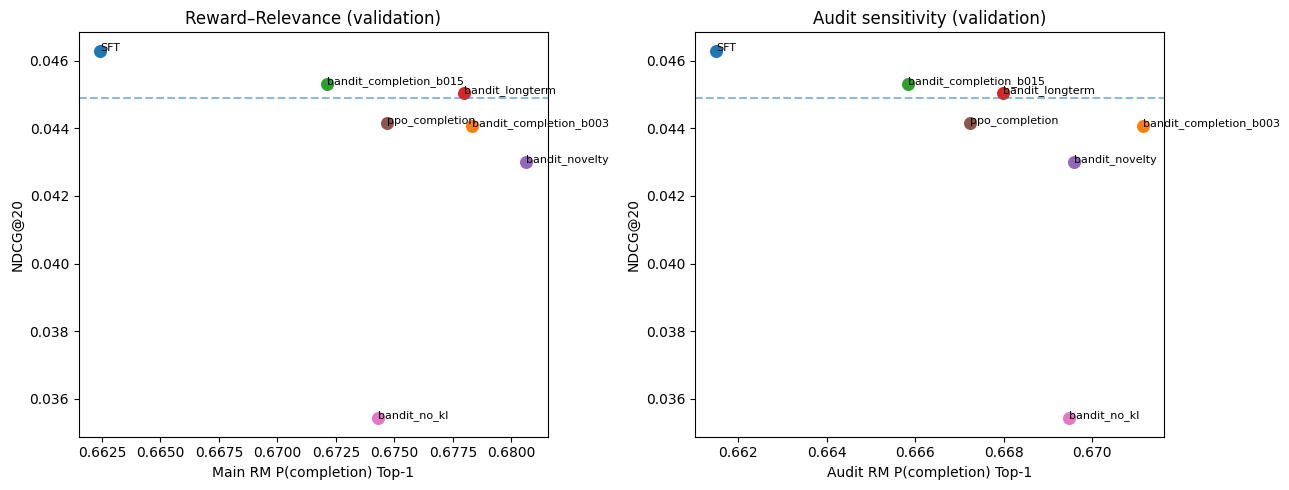

In [13]:
validation_rows = [sft_val_summary]
all_val_arrays = {'SFT':sft_val_arrays}

for spec in RL_EXPERIMENTS:
    path = RUNS_DIR/spec['name']/'best_policy.pt'
    if not path.exists():
        print('Missing checkpoint:',path)
        continue
    ck = torch.load(path,map_location='cpu',weights_only=True)
    validation_rows.append(ck['val'])
    with np.load(RESULTS_DIR/f'val_{spec["name"]}.npz') as f:
        all_val_arrays[spec['name']] = {k:f[k] for k in f.files}

validation_df = pd.DataFrame(validation_rows)
validation_df.to_csv(RESULTS_DIR/'validation_comparison.csv',index=False)
display(validation_df[['name','ndcg@20','recall@20','map@20','main_completion_top1',
                       'audit_completion_top1','candidate_expected_completion','top1_repeat_rate',
                       'top1_unique','top1_max_share','catalog_coverage@20','interuser_jaccard_top20']])


def ndcg_by_query(pred,targets,k=20):
    match = pred[:,:k] == targets[:,None]
    rank = np.where(match.any(1),match.argmax(1)+1,0)
    return np.where(rank>0,1/np.log2(np.maximum(rank,1)+1),0.)


def user_bootstrap(delta,users,seed=SEED,n=BOOTSTRAPS):
    _,group = np.unique(users,return_inverse=True)
    total = np.bincount(group,weights=delta)
    sizes = np.bincount(group)
    rng = np.random.default_rng(seed)
    out = np.empty(n,dtype=np.float64)
    for j in range(n):
        chosen_users = rng.integers(len(total),size=len(total))
        out[j] = total[chosen_users].sum()/sizes[chosen_users].sum()
    return {'delta':float(np.mean(delta)),
            'ci_low':float(np.quantile(out,.025)),
            'ci_high':float(np.quantile(out,.975))}


paired_rows = []
base = all_val_arrays['SFT']
for index,(name,arrays) in enumerate(all_val_arrays.items()):
    if name=='SFT': continue
    if not (np.array_equal(base['targets'],arrays['targets']) and
            np.array_equal(base['users'],arrays['users'])):
        raise ValueError(f'Несовпадение validation-запросов для {name}.')
    rn = ndcg_by_query(arrays['top20'],arrays['targets'])-ndcg_by_query(base['top20'],base['targets'])
    r1 = arrays['main_top1'][:,0]-base['main_top1'][:,0]
    ar = arrays['audit_top1'][:,0]-base['audit_top1'][:,0]
    paired_rows.append({'name':name,
         'changed_top1':float((arrays['top20'][:,0]!=base['top20'][:,0]).mean()),
         'top20_overlap':float(np.mean([np.isin(a,b).mean() for a,b in zip(arrays['top20'],base['top20'])])),
         **{f'ndcg_{k}':v for k,v in user_bootstrap(rn,arrays['users'],SEED+index).items()},
         **{f'main_reward_{k}':v for k,v in user_bootstrap(r1,arrays['users'],SEED+100+index).items()},
         **{f'audit_reward_{k}':v for k,v in user_bootstrap(ar,arrays['users'],SEED+200+index).items()}})
paired_df = pd.DataFrame(paired_rows)
paired_df.to_csv(RESULTS_DIR/'validation_paired_bootstrap.csv',index=False)
display(paired_df)

# Согласованный критерий отбора: completion Top-1 на validation при NDCG floor.
# Audit reward используется ТОЛЬКО для диагностического сравнения, НЕ для выбора.
floor = sft_val_summary['ndcg@20']*(1-NDCG_TOLERANCE)
qualified = validation_df[(validation_df['name']!='SFT') &
                          (validation_df['ndcg@20']>=floor) &
                          (validation_df['main_completion_top1']>sft_val_summary['main_completion_top1'])]
if len(qualified):
    chosen_row = qualified.sort_values('main_completion_top1',ascending=False).iloc[0]
    chosen_name = str(chosen_row['name'])
    selection_status = 'reward_up_with_ndcg_floor'
else:
    alternatives = validation_df[validation_df['name']!='SFT']
    if not len(alternatives):
        raise RuntimeError('Нет готовых RL-политик.')
    chosen_name = str(alternatives.sort_values('ndcg@20',ascending=False).iloc[0]['name'])
    selection_status = 'diagnostic_fallback_NO_eligible_reward_uplift'
selection = {'rl_model_for_test':chosen_name,'status':selection_status,
             'ndcg_floor':float(floor),'criterion':'validation main completion top1 uplift + NDCG floor',
             'audit_not_used_for_selection':True}
(RESULTS_DIR/'selected_model.json').write_text(json.dumps(selection,indent=2,ensure_ascii=False))
print('Selected RL:',selection)

fig,axes = plt.subplots(1,2,figsize=(13,5))
for _,r in validation_df.iterrows():
    axes[0].scatter(r['main_completion_top1'],r['ndcg@20'],s=70)
    axes[0].annotate(r['name'],(r['main_completion_top1'],r['ndcg@20']),fontsize=8)
    axes[1].scatter(r['audit_completion_top1'],r['ndcg@20'],s=70)
    axes[1].annotate(r['name'],(r['audit_completion_top1'],r['ndcg@20']),fontsize=8)
axes[0].set(xlabel='Main RM P(completion) Top-1',ylabel='NDCG@20',title='Reward–Relevance (validation)')
axes[1].set(xlabel='Audit RM P(completion) Top-1',ylabel='NDCG@20',title='Audit sensitivity (validation)')
for ax in axes: ax.axhline(floor,linestyle='--',alpha=.5)
plt.tight_layout()
plt.savefig(RESULTS_DIR/'reward_ndcg_tradeoff.png',dpi=160)
plt.show()

### KL по полному каталогу


In [ ]:
@torch.inference_mode()
def full_kl_on_validation(policy,q,split_starts,batch=8):
    policy.eval()
    total_kl=[]
    for j in tqdm(range(0,len(q),batch),desc='Full catalog KL',leave=False):
        qq=q[j:j+batch]
        x,lengths,_=query_batch(qq,split_starts)
        x,lengths=x.to(DEVICE),lengths.to(DEVICE)
        rows=torch.arange(len(qq),device=DEVICE)
        with torch.autocast('cuda',enabled=AMP_ENABLED):
            ref_h=reference.encode(x)[rows,lengths-1]
            pi_h=policy.encode(x)[rows,lengths-1]
            ref_logits=reference.scores(ref_h).float()
            pi_logits=policy.scores(pi_h).float()
        log_ref=F.log_softmax(ref_logits,dim=1)
        log_pi=F.log_softmax(pi_logits,dim=1)
        kl=(log_pi.exp()*(log_pi-log_ref)).sum(1)
        total_kl.extend(kl.cpu().numpy().tolist())
    return float(np.mean(total_kl))

fixed_kl_q=rl_val_queries[:min(256,len(rl_val_queries))]
kl_rows=[]
for spec in RL_EXPERIMENTS:
    path=RUNS_DIR/spec['name']/'best_policy.pt'
    if not path.exists():continue
    policy=load_policy(path)
    kl_rows.append({'name':spec['name'],
                    'full_catalog_kl':full_kl_on_validation(policy,fixed_kl_q,val_start)})
    del policy
    gc.collect()
full_kl_df=pd.DataFrame(kl_rows)
full_kl_df.to_csv(RESULTS_DIR/'full_catalog_kl_validation.csv',index=False)
display(full_kl_df)
print('Reference Top-100 probability mass:',round(rm_candidate_diagnostics['reference_top100_probability_mass'],4))
print('Conditional KL inside Top-100 is NOT equal to full-catalog KL.')

## 8. Пятишаговая генерация


Rollout SFT:   0%|          | 0/20 [00:00<?, ?it/s]

Rollout bandit_longterm:   0%|          | 0/20 [00:00<?, ?it/s]

,model,step,top1_teacher_agreement,top20_teacher_jaccard,hit20_vs_logged,repeat_rate,reward_completion,reward_return24,popularity
0,SFT,1,1.000000,1.000000,0.075000,0.290625,0.657106,0.802008,0.722174
1,SFT,2,0.356250,0.399481,0.087500,0.978125,0.665918,0.800623,0.725476
2,SFT,3,0.346875,0.328869,0.081250,0.996875,0.671499,0.799171,0.725390
3,SFT,4,0.309375,0.289180,0.071875,0.996875,0.675970,0.797995,0.725323
4,SFT,5,0.265625,0.252435,0.084375,1.000000,0.679037,0.797202,0.725323
5,bandit_longterm,1,1.000000,1.000000,0.078125,0.265625,0.674093,0.805303,0.710986
6,bandit_longterm,2,0.412500,0.404981,0.100000,0.971875,0.687939,0.804787,0.713846
7,bandit_longterm,3,0.331250,0.336175,0.084375,0.996875,0.695763,0.803973,0.713634
8,bandit_longterm,4,0.290625,0.288012,0.084375,1.000000,0.701833,0.803341,0.713871
9,bandit_longterm,5,0.256250,0.255890,0.087500,1.000000,0.705818,0.802724,0.713871


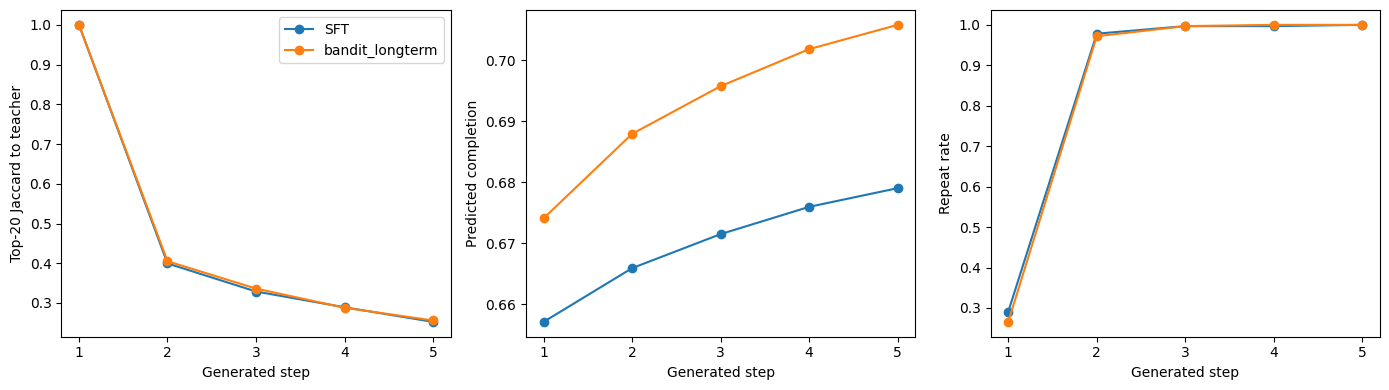

In [15]:
def append_action(x,lengths,actions):
    # Контекст заполняется слева; при длине 128 вытесняем самый старый трек.
    next_x = x.clone()
    next_lengths = lengths.clone()
    room = lengths < x.shape[1]
    j = torch.arange(len(x),device=x.device)
    next_x[j[room],lengths[room]] = actions[room]
    if (~room).any():
        next_x[~room,:-1] = x[~room,1:].clone()
        next_x[~room,-1] = actions[~room]
    next_lengths = torch.minimum(lengths+1,torch.full_like(lengths,x.shape[1]))
    return next_x,next_lengths


@torch.inference_mode()
def rollout_five(policy,name,queries,split_starts,split_ends,steps=ROLLOUT_STEPS):
    valid_q = queries[queries[:,1]+steps<=split_ends[queries[:,0]]]
    rng = np.random.default_rng(SEED+802)
    if len(valid_q)>ROLLOUT_QUERIES:
        valid_q = valid_q[np.sort(rng.choice(len(valid_q),ROLLOUT_QUERIES,replace=False))]
    records=[]
    policy.eval()
    for j in tqdm(range(0,len(valid_q),ROLLOUT_BATCH),desc=f'Rollout {name}',leave=False):
        q = valid_q[j:j+ROLLOUT_BATCH]
        x,lengths,_ = query_batch(q,split_starts)
        x,lengths=x.to(DEVICE),lengths.to(DEVICE)
        for s in range(steps):
            position = torch.arange(len(q),device=DEVICE)
            # teacher context: всё время реальные треки; нет подмешивания сгенерированного
            teacher_q = q.copy()
            teacher_q[:,1] = q[:,1]+s
            x_teacher,length_teacher,_ = query_batch(teacher_q,split_starts)
            x_teacher,length_teacher=x_teacher.to(DEVICE),length_teacher.to(DEVICE)
            with torch.autocast('cuda',enabled=AMP_ENABLED):
                state = policy.encode(x)[position,lengths-1]
                scores = policy.scores(state).float()
                teacher_state = policy.encode(x_teacher)[position,length_teacher-1]
                teacher_scores = policy.scores(teacher_state).float()
                ref_h = reference.encode(x)[position,lengths-1]
            top = scores.topk(20,dim=1).indices+1
            top_teacher = teacher_scores.topk(20,dim=1).indices+1
            action = top[:,0]
            main = reward_model(reward_features(ref_h,action,x)).sigmoid()
            true_next = tokens[q[:,1]+s]
            hits = (top.cpu().numpy() == true_next[:,None]).any(1)
            for k in range(len(q)):
                intersection = np.intersect1d(top[k].cpu().numpy(),top_teacher[k].cpu().numpy()).size
                repeated = bool((x[k]==action[k]).any().item())
                records.append({'model':name,'step':s+1,'user':int(q[k,0]),
                    'free_top1':int(action[k]),'teacher_top1':int(top_teacher[k,0]),
                    'real_next_item':int(true_next[k]),'free_hit20_vs_logged':int(hits[k]),
                    'top1_same_as_teacher':int(action[k]==top_teacher[k,0]),
                    'top20_jaccard_to_teacher':float(intersection/(40-intersection)),
                    'repeated_in_generated_context':int(repeated),
                    'completion_predicted':float(main[k,0].item()),
                    'return_predicted':float(main[k,2].item()),
                    'normalized_popularity':float(train_popularity[action[k]].item())})
            x,lengths = append_action(x,lengths,action)
    return pd.DataFrame(records)

rollout_models = ['SFT',chosen_name]
rollout_frames=[]
for label in dict.fromkeys(rollout_models):
    p=reference if label=='SFT' else load_policy(RUNS_DIR/label/'best_policy.pt')
    rollout_frames.append(rollout_five(p,label,rl_val_queries,val_start,val_end))
    if label!='SFT': del p; gc.collect()
rollout_df = pd.concat(rollout_frames,ignore_index=True)
rollout_df.to_csv(RESULTS_DIR/'five_step_rollouts_validation.csv',index=False)
rollout_summary=rollout_df.groupby(['model','step'],as_index=False).agg(
    top1_teacher_agreement=('top1_same_as_teacher','mean'),
    top20_teacher_jaccard=('top20_jaccard_to_teacher','mean'),
    hit20_vs_logged=('free_hit20_vs_logged','mean'),
    repeat_rate=('repeated_in_generated_context','mean'),
    reward_completion=('completion_predicted','mean'),
    reward_return24=('return_predicted','mean'),
    popularity=('normalized_popularity','mean'))
display(rollout_summary)
fig,axes=plt.subplots(1,3,figsize=(14,4))
for name,g in rollout_summary.groupby('model'):
    axes[0].plot(g['step'],g['top20_teacher_jaccard'],marker='o',label=name)
    axes[1].plot(g['step'],g['reward_completion'],marker='o',label=name)
    axes[2].plot(g['step'],g['repeat_rate'],marker='o',label=name)
for ax,y in zip(axes,['Top-20 Jaccard to teacher','Predicted completion','Repeat rate']):
    ax.set(xlabel='Generated step',ylabel=y,xticks=list(range(1,ROLLOUT_STEPS+1)))
axes[0].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR/'five_step_drift.png',dpi=160)
plt.show()

## 9. Финальная оценка на test


In [ ]:
final_path = RESULTS_DIR/'final_test_summary.json'
if final_path.exists() and not FORCE_TEST_RERUN:
    final_result = json.loads(final_path.read_text())
    print('Final test already evaluated: loaded saved results; no second test query.')
else:
    chosen_policy = load_policy(RUNS_DIR/chosen_name/'best_policy.pt')
    base_test,base_test_arrays = evaluate_policy(reference,test_queries,test_start,'SFT_test',
                                                 RESULTS_DIR/'test_SFT.npz')
    rl_test,rl_test_arrays = evaluate_policy(chosen_policy,test_queries,test_start,f'{chosen_name}_test',
                                            RESULTS_DIR/'test_RL.npz')
    if not (np.array_equal(base_test_arrays['targets'],rl_test_arrays['targets']) and
            np.array_equal(base_test_arrays['users'],rl_test_arrays['users'])):
        raise ValueError('Разные test запросы — парное сравнение невозможно.')
    delta_ndcg = ndcg_by_query(rl_test_arrays['top20'],rl_test_arrays['targets'])-ndcg_by_query(base_test_arrays['top20'],base_test_arrays['targets'])
    delta_reward = rl_test_arrays['main_top1'][:,0]-base_test_arrays['main_top1'][:,0]
    delta_audit = rl_test_arrays['audit_top1'][:,0]-base_test_arrays['audit_top1'][:,0]
    paired_test = {'ndcg20':user_bootstrap(delta_ndcg,base_test_arrays['users'],SEED+900),
                   'main_reward':user_bootstrap(delta_reward,base_test_arrays['users'],SEED+901),
                   'audit_reward':user_bootstrap(delta_audit,base_test_arrays['users'],SEED+902)}
    # RM - только наблюдавшиеся target треки, а не истинные реакции на RL-рекомендации.
    rm_test_feat = cache_features(test_queries,test_start,'reward_test')
    rm_test_y,rm_test_m = labels_for_queries(test_queries,int(timestamps.max())+1)
    test_rm_metrics = {'main':classification_metrics(predict_head(reward_model,rm_test_feat),rm_test_y,rm_test_m),
                       'audit':classification_metrics(predict_head(audit_model,rm_test_feat),rm_test_y,rm_test_m)}
    final_result = {'selected_rl':chosen_name,'selection':selection,'SFT':base_test,
                    'RL':rl_test,'paired_test_bootstrap':paired_test,
                    'observed_reward_model_test_metrics':test_rm_metrics}
    final_path.write_text(json.dumps(final_result,indent=2,ensure_ascii=False))
    del chosen_policy
    gc.collect()
print('FINAL TEST')
display(pd.DataFrame([final_result['SFT'],final_result['RL']])[
    ['name','ndcg@20','recall@20','map@20','main_completion_top1','audit_completion_top1',
     'catalog_coverage@20','top1_unique','top1_max_share','top1_repeat_rate']])
print('Paired bootstrap:',json.dumps(final_result['paired_test_bootstrap'],indent=2))